In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mplfinance as mpf

/Users/hongmo/.venvs/p3env/lib/python3.13/site-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


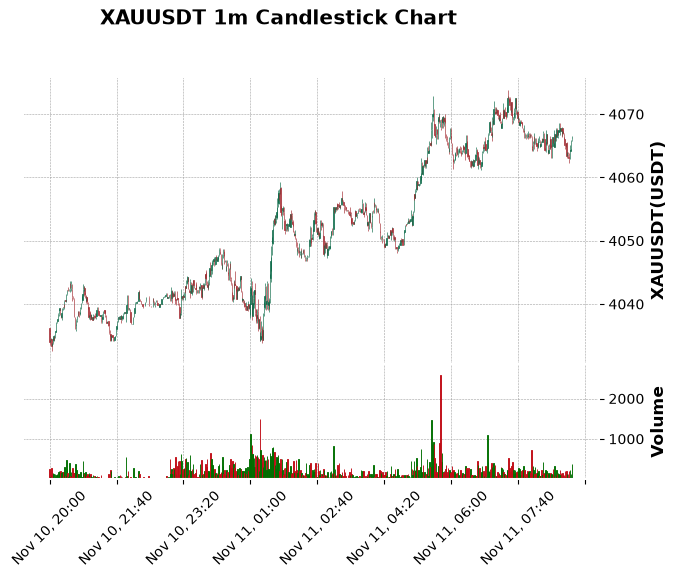

In [ ]:
df = pd.read_csv('binance_xauusdt_1m.csv',
                 parse_dates = ['open_time'],
                 index_col = 'open_time'
                 )

# set datetime as index, because mplfinance requires datetime index
plot_df = df.copy()

plot_df = plot_df.rename(columns={'open': 'Open', 
                                  'high': 'High', 
                                  'low': 'Low', 
                                  'close': 'Close', 
                                  'volume': 'Volume'})

# start time and end time
start = "2026-11-10 20:00"
end = "2026-11-11 9:00"

# filter the time range of the dataframe
xauusdt_df = plot_df.loc[start:end]

# plot the latest 200 candles
mpf.plot(
    xauusdt_df.tail(1000),
    type = 'candle',
    style = 'charles',
    volume = True,
    title = 'XAUUSDT 1m Candlestick Chart',
    ylabel = 'XAUUSDT(USDT)',
    ylabel_lower = 'Volume',
)



In [26]:
df_gc = pd.read_csv('COMEX_GC_data.csv')

df_gc["Datetime"] = pd.to_datetime(
    df_gc["Datetime"],
    utc=True
)

df_gc.to_csv('COMEX_GC_data.csv', index=False)

/Users/hongmo/.venvs/p3env/lib/python3.13/site-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


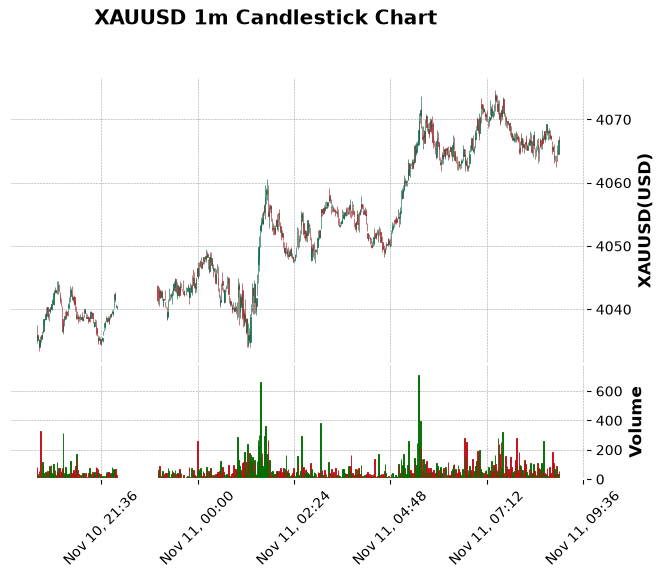

In [32]:
gcdf = pd.read_csv('COMEX_GC_data.csv',
                 parse_dates = ['Datetime'],
                 index_col = 'Datetime'
                 )

# set datetime as index, because mplfinance requires datetime index
plot_df = gcdf.copy()

plot_df = plot_df.rename(columns={'open': 'Open', 
                                  'high': 'High', 
                                  'low': 'Low', 
                                  'close': 'Close', 
                                  'volume': 'Volume'})

# start time and end time
start = "2026-11-10 20:00"
end = "2026-11-11 9:00"

# filter the time range of the dataframe
xauusd_df = plot_df.loc[start:end]

# plot the latest xx candles
mpf.plot(
    xauusd_df.tail(1000),
    type = 'candle',
    style = 'charles',
    volume = True,
    title = 'XAUUSD 1m Candlestick Chart',
    ylabel = 'XAUUSD(USD)',
    ylabel_lower = 'Volume',
    show_nontrading=True
)

In [28]:
def check_gaps(df):
    gaps = df.index.to_series().diff()

    print(gaps[gaps > pd.Timedelta(minutes=1)].head(20))

check_gaps(xauusdt_df)
check_gaps(xauusd_df)

Series([], Name: open_time, dtype: timedelta64[us])
Datetime
2026-11-10 23:00:00+00:00   0 days 01:01:00
2026-11-11 05:00:00+00:00   0 days 00:02:00
Name: Datetime, dtype: timedelta64[us]
